In [1]:
# Import library
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [2]:
# Cari dataset dari direktori kerja notebook hingga root proyek.
data_path = next(
    (
        parent / "data" / "komdigi_hoaks.csv"
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "data" / "komdigi_hoaks.csv").is_file()
    ),
    None,
)
if data_path is None:
    raise FileNotFoundError("File data/komdigi_hoaks.csv tidak ditemukan dari direktori kerja saat ini.")

data = pd.read_csv(data_path)
required_columns = ["url", "title", "excerpt", "body_text", "topics", "published_at", "view_count"]
missing_columns = [column for column in required_columns if column not in data.columns]
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan pada dataset: {missing_columns}")

# Buang artikel duplikat dan data tanpa target; gabungkan teks artikel.
data = data.drop_duplicates(subset="url", keep="first").dropna(subset=["view_count"]).copy()
text_columns = ["title", "excerpt", "body_text"]
data[text_columns] = data[text_columns].fillna("").astype(str)
data["article_text"] = (
    data[text_columns]
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
data["topics"] = data["topics"].fillna("Tidak diketahui").astype(str)
data["published_month"] = (
    pd.to_datetime(data["published_at"], errors="coerce")
    .dt.strftime("%Y-%m")
    .fillna("Tidak diketahui")
)
data["view_count"] = pd.to_numeric(data["view_count"], errors="coerce")
data = data.dropna(subset=["view_count"])
data = data.loc[data["article_text"].ne("")].reset_index(drop=True)

print(f"Lokasi dataset: {data_path.resolve()}")
print("Ukuran dataset setelah pembersihan:", data.shape)
display(data[["title", "topics", "published_month", "view_count"]].head())
data.info()
display(data[["view_count"]].describe())

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran dataset setelah pembersihan: (4162, 15)


,title,topics,published_month,view_count
0,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Hoaks,2026-09,272
1,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,Hoaks,2026-09,156
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Hoaks,2026-09,146
3,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,Hoaks,2026-09,224
4,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,Hoaks,2026-09,309


<class 'pandas.DataFrame'>
RangeIndex: 4162 entries, 0 to 4161
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   id               4162 non-null   int64
 1   url              4162 non-null   str  
 2   title            4162 non-null   str  
 3   slug             4162 non-null   str  
 4   published_at     4162 non-null   str  
 5   view_count       4162 non-null   int64
 6   excerpt          4162 non-null   str  
 7   body_html        4162 non-null   str  
 8   body_text        4162 non-null   str  
 9   main_image_url   4157 non-null   str  
 10  category         4162 non-null   str  
 11  tags             2187 non-null   str  
 12  topics           4162 non-null   str  
 13  article_text     4162 non-null   str  
 14  published_month  4162 non-null   str  
dtypes: int64(2), str(13)
memory usage: 17.5 MB


,view_count
count,4162.000000
mean,1037.881547
std,2354.644194
min,63.000000
25%,352.250000
50%,537.000000
75%,879.000000
max,65813.000000


Jumlah nilai kosong setiap kolom:
topics             0
published_month    0
article_text       0
view_count         0
dtype: int64

Distribusi jumlah tayangan:


,view_count
count,4162.000000
mean,1037.881547
std,2354.644194
min,63.000000
50%,537.000000
75%,879.000000
90%,1763.800000
95%,3048.900000
99%,10362.930000
max,65813.000000


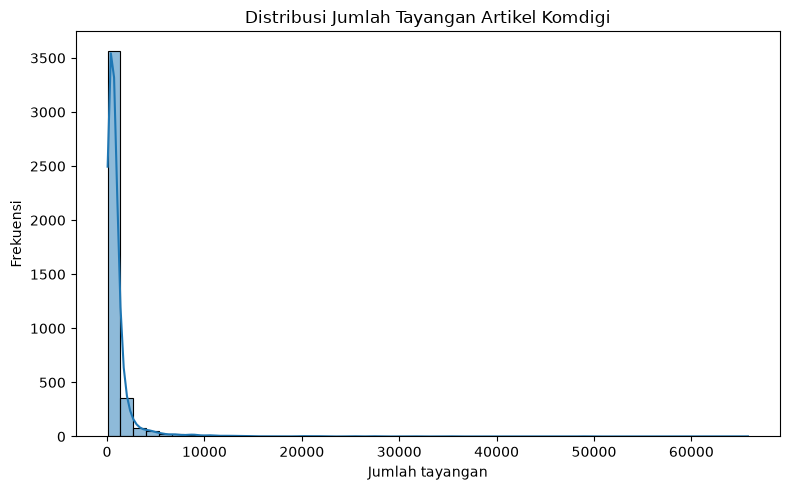

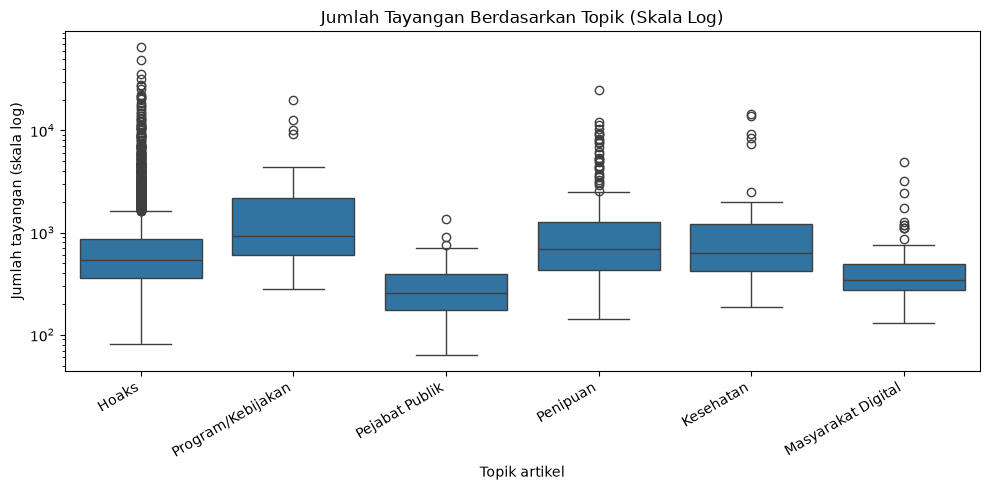

In [3]:
# Periksa nilai kosong dan distribusi target view_count.
print("Jumlah nilai kosong setiap kolom:")
print(data[["topics", "published_month", "article_text", "view_count"]].isnull().sum())

print("\nDistribusi jumlah tayangan:")
display(data["view_count"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).to_frame())

plt.figure(figsize=(8, 5))
sns.histplot(data=data, x="view_count", bins=50, kde=True)
plt.title("Distribusi Jumlah Tayangan Artikel Komdigi")
plt.xlabel("Jumlah tayangan")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x="topics", y="view_count")
plt.yscale("log")
plt.title("Jumlah Tayangan Berdasarkan Topik (Skala Log)")
plt.xlabel("Topik artikel")
plt.ylabel("Jumlah tayangan (skala log)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [4]:
# Teks artikel, topik, dan bulan publikasi menjadi fitur untuk regresi.
feature_columns = ["article_text", "topics", "published_month"]
X = data[feature_columns]
y = data["view_count"].astype(float)

print("Fitur:", feature_columns)
print("Target numerik:", "view_count")
print("Rentang target:", f"{y.min():.0f} sampai {y.max():.0f} tayangan")

# Pisahkan data latih dan data uji.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)
print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

Fitur: ['article_text', 'topics', 'published_month']
Target numerik: view_count
Rentang target: 63 sampai 65813 tayangan
Jumlah data latih: 3329
Jumlah data uji: 833


In [5]:
# TF-IDF mewakili teks; One-Hot Encoding mewakili topik dan bulan publikasi.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                max_features=10000,
                min_df=2,
                ngram_range=(1, 2),
                sublinear_tf=True,
            ),
            "article_text",
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["topics", "published_month"],
        ),
    ]
)

# Regresi linear berganda dilatih pada log1p(view_count) untuk mengurangi
# pengaruh ekor panjang; prediksi dikembalikan ke skala jumlah tayangan.
linear_regression = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression()),
    ]
)
model = TransformedTargetRegressor(
    regressor=linear_regression,
    func=np.log1p,
    inverse_func=np.expm1,
)
model.fit(X_train, y_train)
print("Model regresi linear berganda berhasil dilatih.")

Model regresi linear berganda berhasil dilatih.


In [6]:
# Bandingkan hasil model dengan baseline yang selalu memprediksi rerata data latih.
y_pred = model.predict(X_test)
baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_pred = baseline.predict(np.zeros((len(y_test), 1)))

def tampilkan_metrik(nama_model, y_true, predictions):
    mse = mean_squared_error(y_true, predictions)
    print(f"=== {nama_model} ===")
    print(f"R-squared (R2): {r2_score(y_true, predictions):.4f}")
    print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_true, predictions):.2f} tayangan")
    print(f"Root Mean Squared Error (RMSE): {np.sqrt(mse):.2f} tayangan")

tampilkan_metrik("Regresi Linear Berganda", y_test, y_pred)
print()
tampilkan_metrik("Baseline (rerata data latih)", y_test, baseline_pred)

=== Regresi Linear Berganda ===
R-squared (R2): 0.0103
Mean Absolute Error (MAE): 918.73 tayangan
Root Mean Squared Error (RMSE): 3260.01 tayangan

=== Baseline (rerata data latih) ===
R-squared (R2): -0.0020
Mean Absolute Error (MAE): 961.46 tayangan
Root Mean Squared Error (RMSE): 3280.14 tayangan


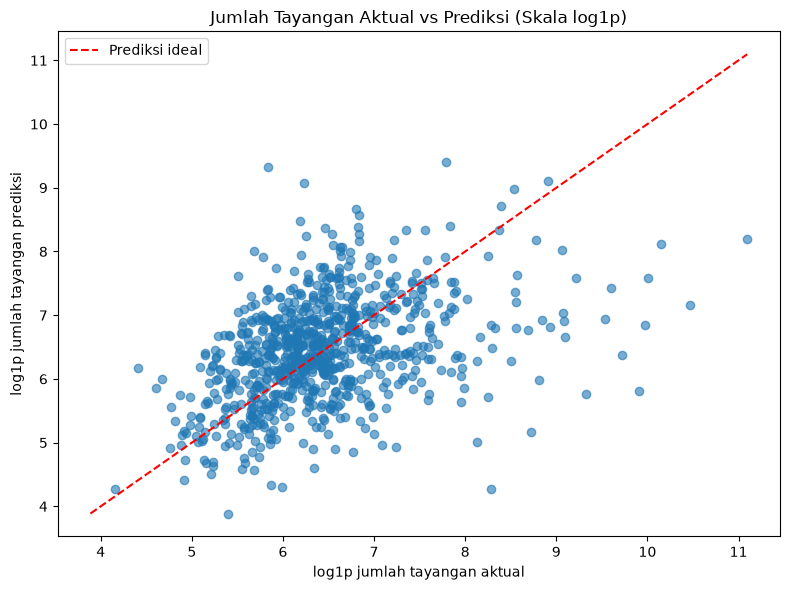

In [7]:
# Bandingkan nilai aktual dan prediksi pada skala log1p agar ekor panjang terbaca.
plt.figure(figsize=(8, 6))
plt.scatter(np.log1p(y_test), np.log1p(y_pred), alpha=0.6)

min_value = min(np.log1p(y_test).min(), np.log1p(y_pred).min())
max_value = max(np.log1p(y_test).max(), np.log1p(y_pred).max())
plt.plot([min_value, max_value], [min_value, max_value], "--", color="red", label="Prediksi ideal")
plt.title("Jumlah Tayangan Aktual vs Prediksi (Skala log1p)")
plt.xlabel("log1p jumlah tayangan aktual")
plt.ylabel("log1p jumlah tayangan prediksi")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# Koefisien menunjukkan hubungan fitur dengan log1p jumlah tayangan.
fitted_pipeline = model.regressor_
feature_names = fitted_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = fitted_pipeline.named_steps["regressor"].coef_

coef_df = pd.DataFrame({
    "Fitur": feature_names,
    "Koefisien pada skala log1p": coefficients,
})
coef_df["Nilai Absolut"] = coef_df["Koefisien pada skala log1p"].abs()
display(coef_df.nlargest(20, "Nilai Absolut").drop(columns="Nilai Absolut"))

,Fitur,Koefisien pada skala log1p
8253,text__selanjutnya,3.273505
6685,text__pemasangan,2.909723
2380,text__diabetes,2.790005
3791,text__internet,2.741387
9233,text__tingkat,2.676860
7348,text__pinjol,2.607401
3885,text__jadwal,-2.602493
1116,text__bbm subsidi,2.602394
9010,text__tersebut dalam,2.533692
5922,text__merek,2.442061


### Analisis Hasil Regresi Linear Berganda

Pada tugas ini, dataset `komdigi_hoaks.csv` digunakan untuk memperkirakan jumlah tayangan artikel (`view_count`). Fitur prediksi terdiri dari gabungan teks judul, ringkasan, dan isi artikel, kategori `topics`, serta bulan publikasi. `topics` merupakan kategori artikel dan bukan label benar atau salahnya klaim.

Data dibagi menjadi 80% data latih dan 20% data uji. TF-IDF mengubah teks menjadi fitur numerik, sedangkan topik dan bulan publikasi diproses dengan One-Hot Encoding. Regresi Linear Berganda dilatih pada `log1p(view_count)` karena distribusi tayangan memiliki ekor panjang. Prediksi dikembalikan ke skala jumlah tayangan asli sebelum evaluasi.

Kinerja diukur menggunakan R-squared, MAE, dan RMSE serta dibandingkan dengan baseline yang selalu memprediksi rerata jumlah tayangan data latih. MAE dan RMSE dilaporkan dalam satuan tayangan. Nilai metrik yang tercetak saat notebook dijalankan menjadi acuan untuk menilai apakah model mengungguli baseline. Grafik aktual vs prediksi ditampilkan pada skala `log1p`, sementara tabel koefisien berada pada skala target transformasi.

Jumlah tayangan mungkin dipengaruhi faktor yang tidak tersedia dalam dataset, misalnya promosi atau posisi penayangan. Karena itu, hasil model merupakan estimasi berdasarkan fitur yang ada dan tidak menunjukkan hubungan sebab-akibat.

**Kesimpulan:** gunakan nilai evaluasi pada data uji dan perbandingan terhadap baseline untuk menentukan kemampuan model memperkirakan jumlah tayangan artikel Komdigi.